# Proyecto 2 · Clasificación: diagnóstico de tumores de mama

**Objetivo:** predecir si un tumor es **maligno** o **benigno** a partir de 30 medidas de sus células, comparando los clasificadores de la parte de machine learning del bootcamp: regresión logística, K vecinos más cercanos (KNN), árbol de decisión, bosque aleatorio y máquinas de vectores de soporte (SVM).

Es el dataset que el curso usa en la clase de SVM (*Breast Cancer Wisconsin*). Viene incluido en scikit-learn.

**Criterio de éxito:** en un diagnóstico, dejar pasar un tumor maligno (falso negativo) es mucho más grave que una falsa alarma. Por eso, además de la exactitud, la métrica que manda es el **recall de la clase maligna**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, recall_score, accuracy_score, roc_auc_score
from sklearn.exceptions import UndefinedMetricWarning
import warnings
warnings.filterwarnings('ignore', category=UndefinedMetricWarning)  # la línea base nunca predice "maligno": su precisión no está definida

sns.set_theme(style='whitegrid')
SEMILLA = 42
datos = load_breast_cancer(as_frame=True)
X = datos.data
y = 1 - datos.target           # en scikit-learn 0 = maligno; se invierte para que 1 = maligno (la clase "positiva")
print(X.shape)
y.map({1: 'maligno', 0: 'benigno'}).value_counts()

(569, 30)


target
benigno    357
maligno    212
Name: count, dtype: int64

## Exploración rápida

Las 30 columnas son 10 medidas del núcleo celular (radio, textura, perímetro, área…) en tres versiones: media, error estándar y "peor" valor. Las escalas son muy distintas: el área está en cientos y la suavidad en centésimas.

In [2]:
X[['mean radius', 'mean texture', 'mean area', 'mean smoothness', 'worst concave points']].describe().round(3)

,mean radius,mean texture,mean area,mean smoothness,worst concave points
count,569.000,569.000,569.000,569.000,569.000
mean,14.127,19.290,654.889,0.096,0.115
std,3.524,4.301,351.914,0.014,0.066
min,6.981,9.710,143.500,0.053,0.000
25%,11.700,16.170,420.300,0.086,0.065
50%,13.370,18.840,551.100,0.096,0.100
75%,15.780,21.800,782.700,0.105,0.161
max,28.110,39.280,2501.000,0.163,0.291


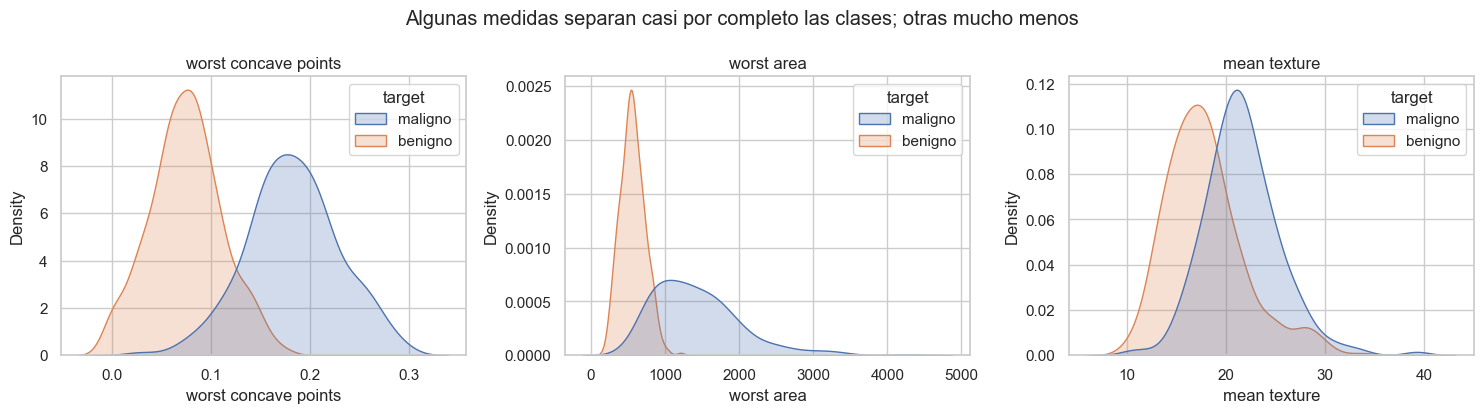

In [3]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.2))
etiqueta = y.map({1: 'maligno', 0: 'benigno'})
for eje, col in zip(ejes, ['worst concave points', 'worst area', 'mean texture']):
    sns.kdeplot(x=X[col], hue=etiqueta, fill=True, common_norm=False, ax=eje)
    eje.set_title(col)
plt.suptitle('Algunas medidas separan casi por completo las clases; otras mucho menos')
plt.tight_layout()
plt.savefig('../imagenes/clasificacion-distribuciones.png', dpi=110, bbox_inches='tight')
plt.show()

## División

70/30 **estratificada**: hay más benignos que malignos (63/37), y ambas partes deben conservar esa proporción.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEMILLA)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f'Entrenamiento: {len(X_train)} · Prueba: {len(X_test)}')

Entrenamiento: 398 · Prueba: 171


## Elegir `k` para KNN: el método del codo de la tasa de error

Como en la sección de KNN del curso: se prueba `k` de 1 a 40 y se mira la tasa de error. Aquí con validación cruzada en vez de un único reparto, y con escalado, que KNN necesita porque compara distancias.

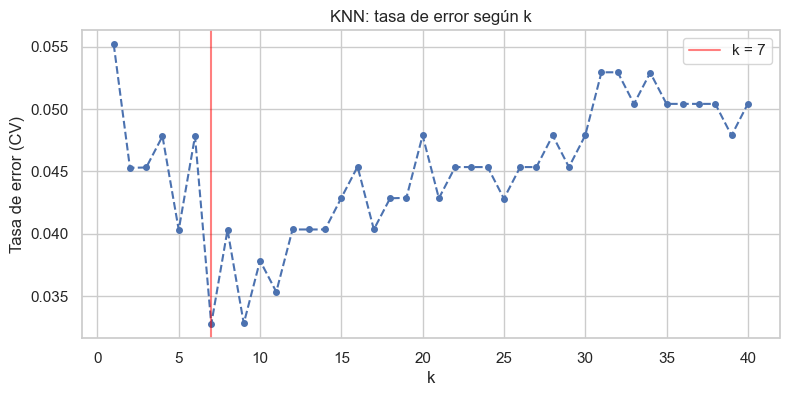

k con menor error: 7 (0.033)


In [5]:
ks = range(1, 41)
error = [1 - cross_val_score(Pipeline([('escala', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=k))]),
                             X_train, y_train, cv=cv).mean() for k in ks]
k_mejor = ks[int(np.argmin(error))]

plt.figure(figsize=(9, 4))
plt.plot(ks, error, 'o--', markersize=4)
plt.axvline(k_mejor, color='red', alpha=0.5, label=f'k = {k_mejor}')
plt.xlabel('k'); plt.ylabel('Tasa de error (CV)'); plt.title('KNN: tasa de error según k')
plt.legend()
plt.savefig('../imagenes/clasificacion-knn-codo.png', dpi=110, bbox_inches='tight')
plt.show()
print(f'k con menor error: {k_mejor} ({min(error):.3f})')

## Comparación de clasificadores (validación cruzada, 5 pliegues)

In [6]:
escalar = lambda m: Pipeline([('escala', StandardScaler()), ('modelo', m)])
candidatos = {
    'Clase más frecuente (línea base)': DummyClassifier(strategy='most_frequent'),
    'Regresión logística': escalar(LogisticRegression(max_iter=5000)),
    f'KNN (k={k_mejor})': escalar(KNeighborsClassifier(n_neighbors=k_mejor)),
    'Árbol de decisión': DecisionTreeClassifier(random_state=SEMILLA),
    'Bosque aleatorio': RandomForestClassifier(n_estimators=300, random_state=SEMILLA),
    'SVM (por defecto)': escalar(SVC(random_state=SEMILLA)),
}

filas = []
for nombre, modelo in candidatos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=['accuracy', 'recall', 'precision', 'f1', 'roc_auc'])
    filas.append({'Modelo': nombre, 'Exactitud': r['test_accuracy'].mean(), 'Recall maligno': r['test_recall'].mean(),
                  'Precisión maligno': r['test_precision'].mean(), 'F1': r['test_f1'].mean(),
                  'AUC': r['test_roc_auc'].mean(), 'Recall desv.': r['test_recall'].std()})
tabla_cv = pd.DataFrame(filas).set_index('Modelo').sort_values('Recall maligno', ascending=False)
tabla_cv.round(3)

,Exactitud,Recall maligno,Precisión maligno,F1,AUC,Recall desv.
Modelo,,,,,,
Regresión logística,0.982,0.953,1.000,0.976,0.993,0.017
SVM (por defecto),0.972,0.946,0.979,0.961,0.993,0.042
KNN (k=7),0.967,0.925,0.985,0.954,0.985,0.051
Bosque aleatorio,0.947,0.925,0.938,0.929,0.983,0.060
Árbol de decisión,0.920,0.891,0.898,0.892,0.914,0.055
Clase más frecuente (línea base),0.628,0.000,0.000,0.000,0.500,0.000


## Ajuste de hiperparámetros del SVM con búsqueda en cuadrícula

Como en la sección de SVM del curso: `C` (cuánto se penalizan los errores de entrenamiento) y `gamma` (cuánto alcance tiene cada punto en la frontera). Se optimiza el recall de la clase maligna.

In [7]:
grid = GridSearchCV(escalar(SVC(random_state=SEMILLA)),
                    {'modelo__C': [0.1, 1, 10, 100], 'modelo__gamma': ['scale', 0.001, 0.01, 0.1]},
                    scoring='recall', cv=cv)
grid.fit(X_train, y_train)
print('Mejores hiperparámetros:', grid.best_params_)
print(f'Recall maligno (CV): {grid.best_score_:.3f}')

Mejores hiperparámetros: {'modelo__C': 10, 'modelo__gamma': 'scale'}
Recall maligno (CV): 0.952


## Evaluación final en el conjunto de prueba

In [8]:
finalistas = {nombre: m for nombre, m in candidatos.items() if 'línea base' not in nombre}
finalistas['SVM (ajustado)'] = grid.best_estimator_

filas, entrenados = [], {}
for nombre, modelo in finalistas.items():
    modelo.fit(X_train, y_train)
    entrenados[nombre] = modelo
    pred = modelo.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    puntaje = modelo.decision_function(X_test) if hasattr(modelo, 'decision_function') else modelo.predict_proba(X_test)[:, 1]
    filas.append({'Modelo': nombre, 'Exactitud': accuracy_score(y_test, pred), 'Recall maligno': recall_score(y_test, pred),
                  'AUC': roc_auc_score(y_test, puntaje), 'Malignos no detectados (FN)': cm[1, 0], 'Falsas alarmas (FP)': cm[0, 1]})
tabla_test = pd.DataFrame(filas).set_index('Modelo').sort_values(['Malignos no detectados (FN)', 'Falsas alarmas (FP)'])
tabla_test.round(3)

,Exactitud,Recall maligno,AUC,Malignos no detectados (FN),Falsas alarmas (FP)
Modelo,,,,,
Bosque aleatorio,0.977,0.938,0.996,4,0
Regresión logística,0.971,0.938,0.998,4,1
SVM (ajustado),0.971,0.938,0.995,4,1
KNN (k=7),0.965,0.906,0.987,6,0
SVM (por defecto),0.959,0.891,0.997,7,0
Árbol de decisión,0.901,0.844,0.889,10,7


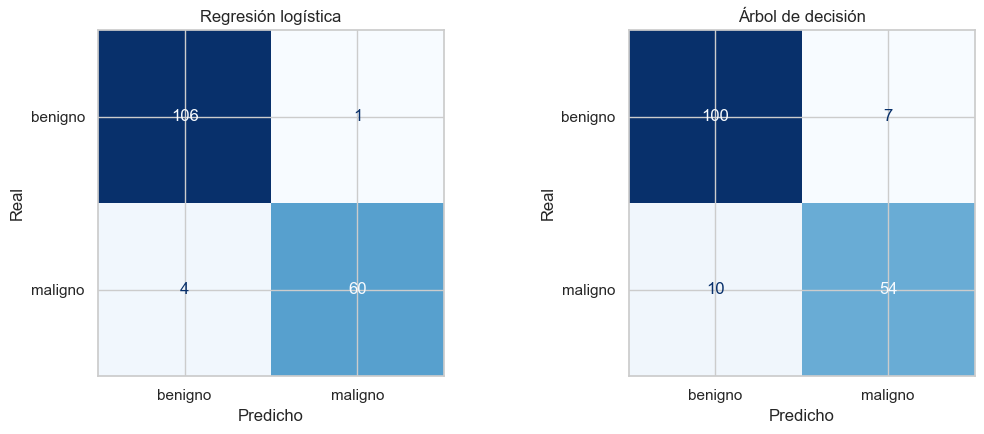

Regresión logística

              precision    recall  f1-score   support

     benigno      0.964     0.991     0.977       107
     maligno      0.984     0.938     0.960        64

    accuracy                          0.971       171
   macro avg      0.974     0.964     0.968       171
weighted avg      0.971     0.971     0.971       171



In [9]:
elegido = tabla_cv.index[0]  # se elige por validación cruzada; la prueba solo confirma
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for eje, nombre in zip(ejes, [elegido, 'Árbol de decisión']):
    ConfusionMatrixDisplay(confusion_matrix(y_test, entrenados[nombre].predict(X_test)),
                           display_labels=['benigno', 'maligno']).plot(ax=eje, cmap='Blues', colorbar=False)
    eje.set_title(nombre); eje.set_xlabel('Predicho'); eje.set_ylabel('Real')
plt.tight_layout()
plt.savefig('../imagenes/clasificacion-matrices.png', dpi=110, bbox_inches='tight')
plt.show()

print(f'{elegido}\n')
print(classification_report(y_test, entrenados[elegido].predict(X_test), target_names=['benigno', 'maligno'], digits=3))

## ¿Qué medidas pesan más? (bosque aleatorio)

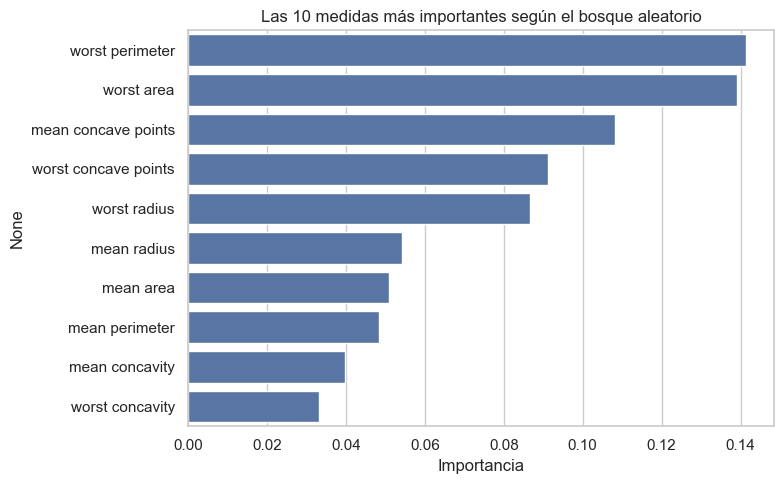

worst perimeter         0.141
worst area              0.139
mean concave points     0.108
worst concave points    0.091
worst radius            0.087
mean radius             0.054
mean area               0.051
mean perimeter          0.049
mean concavity          0.040
worst concavity         0.033
dtype: float64

In [10]:
importancia = pd.Series(entrenados['Bosque aleatorio'].feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=importancia.head(10).values, y=importancia.head(10).index)
plt.title('Las 10 medidas más importantes según el bosque aleatorio'); plt.xlabel('Importancia')
plt.tight_layout()
plt.savefig('../imagenes/clasificacion-importancia.png', dpi=110, bbox_inches='tight')
plt.show()
importancia.head(10).round(3)

## Conclusiones

- **Modelo elegido: regresión logística.** Es la mejor en validación cruzada en todas las métricas (recall maligno 0.953, precisión 1.000, AUC 0.993) y la más estable (desviación del recall 0.017, la menor de todas). Además es la más interpretable.
- **En la prueba confirma:** exactitud 0.971, recall maligno 0.938, AUC 0.998. Detecta 60 de los 64 tumores malignos, con 1 sola falsa alarma.
- **Tres modelos empatan en la prueba** (regresión logística, bosque aleatorio y SVM ajustado: 4 malignos no detectados cada uno). Ese empate es justo la razón para elegir con la validación cruzada y no con la prueba: con 64 malignos, un caso de diferencia mueve el recall más de 1.5 puntos.
- **KNN:** la tasa de error mínima se alcanza con k = 7 (0.033). Sin escalar, KNN compararía distancias dominadas por `area`, que está en cientos.
- **Búsqueda en cuadrícula del SVM:** `C=10` con `gamma='scale'` sube el recall en CV de 0.946 a 0.952. En la prueba, el ajustado pasa de 7 malignos no detectados a 4.
- **El árbol de decisión solo es claramente el peor:** 10 malignos no detectados y 7 falsas alarmas en la prueba. El bosque aleatorio, que promedia muchos árboles, corrige casi todo eso.
- **Lo que más pesa** según el bosque: el tamaño del tumor en su peor zona (`worst perimeter`, `worst area`) y la concavidad del contorno (`concave points`).

**Siguiente paso:** el mejor modelo sigue dejando pasar 4 de 64 malignos (6%). En un caso real habría que **bajar el umbral de decisión**: aceptar más falsas alarmas a cambio de no perder tumores malignos.